# 4. Mechanism: why does temptation change which bias evolves?

**The puzzle.** Optimism evolves when the temptation to defect is high (T = 5), but not when it is low
(T = 3.5); with high noise, pessimism evolves instead. Why?

**The idea (expectiles).** An agent with α⁺ ≠ α⁻ does not learn the *average* value of an action. Its values
settle on an **expectile** of the outcomes, at level **τ = α⁺/(α⁺ + α⁻)**:
* τ = 0.5 → the average (unbiased learner)
* τ > 0.5 → leans toward the good outcomes (optimist: "values things by their good days")
* τ < 0.5 → leans toward the bad outcomes (pessimist: "values things by their bad days")

(Palminteri & Lebreton, 2022, link these biases to distributional RL in this way.)

**Plan**
1. Build intuition: what an expectile is, and a check that asymmetric learners really converge to one.
2. Evolve two resident populations: **high temptation** (T = 5, noise 0.05) and **low temptation** (T = 3.5, noise 0.20).
3. **Fitness landscape:** drop in test agents with every τ from 0.05 to 0.95 (same overall learning speed) and
   measure how much each earns against the residents. Evolution should favour the τ that earns most.
4. **Behaviour:** what do agents with different τ learn to *do* (cooperate or defect, after which partner move)?
5. **Expectiles of real outcomes:** take the outcomes agents actually experience after cooperating vs defecting,
   and compute their expectiles. At which τ does cooperating start to *look* better than defecting?

**Expectations (to check, not assume):** if the idea is right, the best τ in step 3 should be high in the
high-temptation world and low in the low-temptation world, and step 5 should show the C-vs-D ranking depending
on τ differently in the two worlds. If the picture is messy, speed of learning (not just the final values)
probably matters too: that is also a result.

Runtime: a few minutes.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Model code
The full contents of `evolution.py` and `mechanism.py`, so this notebook runs on its own (e.g. in Colab).

In [2]:
"""
evolution.py -- Evolving learning biases (alpha+, alpha-) in populations
=========================================================================
Project: Does evolution favour optimistic learners in social dilemmas?

Each generation:
  1. Every agent lives one "lifetime" in an environment and learns with its
     own (alpha_pos, alpha_neg).  Fitness = mean reward obtained.
  2. Parents are sampled with probability increasing in fitness
     (rank-based selection, Wright-Fisher style).
  3. Offspring inherit their parent's (alpha_pos, alpha_neg) + Gaussian mutation.

Environments (same evolutionary loop):
  * bandit_lifetime            individual learning, myopic (gamma = 0)
                               -> conceptual replication of Hoxha, Sperber &
                                  Palminteri (2025, PNAS)
  * bandit_lifetime_farsighted individual learning, farsighted (gamma > 0) -- control
  * ipd_lifetime               multi-agent learning: agents learn against each other
                               in the Iterated Prisoner's Dilemma -- extension
  * random_lifetime            fitness is pure noise -- neutral-drift control

Scaling conventions (applied in every environment, so conditions are comparable):
  * Payoffs lie in [0, 1].
  * Starting values  Q0 = 0.5 / (1 - gamma)   (neutral given the discount factor)
  * Softmax is applied to (1 - gamma) * Q      (same choice noise for any gamma)
Both can be overridden (q_init=..., rescale=False) to reproduce the original,
flawed settings discussed in the README.

Everything is vectorised over the population with NumPy.
"""

import numpy as np


def softmax_choice(Q, beta, rng):
    """Vectorised softmax over the last axis. Q: (n, 2). Returns actions (n,)."""
    z = beta * (Q - Q.max(axis=1, keepdims=True))
    p1 = np.exp(z[:, 1]) / np.exp(z).sum(axis=1)
    return (rng.random(len(Q)) < p1).astype(int)


def asym_update(q, delta, a_pos, a_neg):
    """Asymmetric learning-rate update, vectorised."""
    lr = np.where(delta > 0, a_pos, a_neg)
    return q + lr * delta


def neutral_q(gamma):
    """Neutral starting value: midpoint payoff (0.5) summed over the discounted future."""
    return 0.5 / (1 - gamma)


# ------------------------------------------------------------------
# Lifetimes
# ------------------------------------------------------------------
def bandit_lifetime_farsighted(a_pos, a_neg, rng, probs=(0.25, 0.75), n_trials=100,
                               beta=10.0, gamma=0.9, q_init=None, rescale=True):
    """Each agent independently learns a 2-armed Bernoulli bandit.
    Arm positions are randomised per agent. Returns fitness (n,)."""
    n = len(a_pos)
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    best = rng.integers(0, 2, n)                       # which arm is better
    p = np.where(best[:, None] == np.arange(2), probs[1], probs[0])  # (n, 2)
    Q = np.full((n, 2), float(q_init))
    total = np.zeros(n)
    idx = np.arange(n)
    for _ in range(n_trials):
        a = softmax_choice(Q * scale, beta, rng)
        r = (rng.random(n) < p[idx, a]).astype(float)
        delta = r + gamma * Q.max(axis=1) - Q[idx, a]
        Q[idx, a] = asym_update(Q[idx, a], delta, a_pos, a_neg)
        total += r
    return total / n_trials


def bandit_lifetime(a_pos, a_neg, rng, **kw):
    """Myopic bandit (gamma = 0): the standard individual-learning task."""
    kw.setdefault("gamma", 0.0)
    return bandit_lifetime_farsighted(a_pos, a_neg, rng, **kw)


def make_pd(temptation=5.0, reward=3.0, punishment=1.0, sucker=0.0, payoff_scale=None):
    """PD payoff matrix PD[my_action, their_action].
    By default divided by T (min-max scaling to [0, 1], since S = 0). With a fixed
    payoff_scale (e.g. 5.5 = the largest T used), the gaps between outcomes no
    longer change with T, so choice noise under a fixed beta is comparable across T."""
    scale = temptation if payoff_scale is None else payoff_scale
    return np.array([[reward, sucker],
                     [temptation, punishment]], dtype=float) / scale


def ipd_lifetime(a_pos, a_neg, rng, n_rounds=100, n_partners=4, noise=0.05,
                 beta=10.0, gamma=0.9, q_init=None, rescale=True,
                 temptation=5.0, payoff_scale=None, log=None):
    """Agents are randomly paired and play the iterated PD, learning online
    (state = partner's last move; 2 = first round). Repeated with
    n_partners random pairings; Q-values are reset for each new partner and the
    first round with each partner uses state 2 ("no history").
    Returns fitness (n,) = mean payoff per round.
    If log is a list, appends (realised cooperation, intended cooperation), where
    intended = the agent's choice before the trembling-hand flip."""
    n = len(a_pos)
    assert n % 2 == 0
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    pd = make_pd(temptation, payoff_scale=payoff_scale)
    fitness = np.zeros(n)
    coop = coop_int = 0.0
    for _ in range(n_partners):
        perm = rng.permutation(n)
        i, j = perm[: n // 2], perm[n // 2:]            # pair i[k] with j[k]
        Q = np.full((n, 3, 2), float(q_init))           # fresh learning per partner
        s = np.full(n, 2)
        idx = np.arange(n)
        for _ in range(n_rounds):
            a = softmax_choice(Q[idx, s] * scale, beta, rng)
            coop_int += (a == 0).mean()
            flip = rng.random(n) < noise                # trembling hand
            a = np.where(flip, 1 - a, a)
            partner_a = np.empty(n, dtype=int)
            partner_a[i], partner_a[j] = a[j], a[i]
            r = pd[a, partner_a]
            coop += (a == 0).mean()
            s_next = partner_a                          # observe partner's move
            target = r + gamma * Q[idx, s_next].max(axis=1)
            delta = target - Q[idx, s, a]
            Q[idx, s, a] = asym_update(Q[idx, s, a], delta, a_pos, a_neg)
            s = s_next
            fitness += r
    if log is not None:                                 # optional: record cooperation
        log.append((coop / (n_rounds * n_partners), coop_int / (n_rounds * n_partners)))
    return fitness / (n_rounds * n_partners)


def random_lifetime(a_pos, a_neg, rng, **_):
    """Control: fitness is pure noise, unrelated to (alpha+, alpha-).
    Shows what mutation + clipping + drift alone do to the optimism index."""
    return rng.random(len(a_pos))


# ------------------------------------------------------------------
# Evolutionary loop
# ------------------------------------------------------------------
def evolve(lifetime, n_agents=100, n_generations=150, mut_sd=0.03,
           selection=2.0, init="uniform", seed=0, **env_kwargs):
    """Run evolution. Returns dict of per-generation traces."""
    rng = np.random.default_rng(seed)
    if init == "uniform":
        a_pos = rng.uniform(0.05, 0.95, n_agents)
        a_neg = rng.uniform(0.05, 0.95, n_agents)
    else:                                               # start unbiased
        a_pos = np.full(n_agents, init)
        a_neg = np.full(n_agents, init)

    trace = {k: [] for k in ("a_pos", "a_neg", "bias", "fitness", "coop", "coop_intended")}
    for g in range(n_generations):
        log = []
        if lifetime is ipd_lifetime:
            fit = lifetime(a_pos, a_neg, rng, log=log, **env_kwargs)
        else:
            fit = lifetime(a_pos, a_neg, rng, **env_kwargs)
        trace["coop"].append(log[0][0] if log else np.nan)
        trace["coop_intended"].append(log[0][1] if log else np.nan)
        bias = (a_pos - a_neg) / (a_pos + a_neg)
        trace["a_pos"].append(a_pos.mean())
        trace["a_neg"].append(a_neg.mean())
        trace["bias"].append(bias.mean())
        trace["fitness"].append(fit.mean())

        # rank-based selection: P(parent) ~ exp(selection * rank / n)
        ranks = fit.argsort().argsort() / (n_agents - 1)
        w = np.exp(selection * ranks); w /= w.sum()
        parents = rng.choice(n_agents, size=n_agents, p=w)
        a_pos = np.clip(a_pos[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)
        a_neg = np.clip(a_neg[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)

    out = {k: np.array(v) for k, v in trace.items()}
    out["final_a_pos"], out["final_a_neg"] = a_pos, a_neg    # final population (for distributions)
    return out


def summarise(runs, last=30):
    """Mean and SE (across seeds) of the optimism index over the last generations,
    plus mean cooperation."""
    b = np.array([r["bias"][-last:].mean() for r in runs])
    def coop(key):
        if np.all(np.isnan(runs[0][key])):
            return np.nan
        return np.mean([r[key][-last:].mean() for r in runs])
    return dict(optimism=b.mean(), se=b.std(ddof=1) / np.sqrt(len(b)),
                cooperation=coop("coop"), cooperation_intended=coop("coop_intended"),
                a_pos=np.mean([r["a_pos"][-last:].mean() for r in runs]),
                a_neg=np.mean([r["a_neg"][-last:].mean() for r in runs]))


In [3]:
"""
mechanism.py -- Why does the temptation to defect change which learning bias evolves?
======================================================================================
Requires the functions in evolution.py (make_pd, neutral_q, softmax_choice, asym_update).

Key idea (Palminteri & Lebreton, 2022):
  With asymmetric learning rates, a Q-value does not converge to the MEAN of the
  outcomes it sees, but to an EXPECTILE of them, at level

        tau = alpha+ / (alpha+ + alpha-)

  tau = 0.5 -> the mean (unbiased learner)
  tau > 0.5 -> leans toward the good outcomes ("values things by their good days")
  tau < 0.5 -> leans toward the bad outcomes ("values things by their bad days")

Tools in this file:
  expectile()          compute the tau-expectile of a sample
  ipd_invasion()       drop "test" agents with chosen (alpha+, alpha-) into an
                       evolved population and measure how well they do
  tau_to_rates()       convert (tau, total learning rate) into (alpha+, alpha-)
"""

import numpy as np


def expectile(x, tau, tol=1e-10, max_iter=500):
    """tau-expectile of the sample x.

    Definition: the value m that balances weighted gains and losses,
        tau * sum(x - m for x above m) = (1 - tau) * sum(m - x for x below m)
    Solved by iterating m = weighted mean of x, with weight tau above m and
    (1 - tau) below m. tau = 0.5 gives the ordinary mean.
    """
    x = np.asarray(x, dtype=float)
    m = x.mean()
    for _ in range(max_iter):
        w = np.where(x > m, tau, 1 - tau)
        m_new = np.sum(w * x) / np.sum(w)
        if abs(m_new - m) < tol:
            break
        m = m_new
    return m


def tau_to_rates(tau, total):
    """(tau, alpha+ + alpha-) -> (alpha+, alpha-). Keeps overall learning speed fixed
    so that only the *asymmetry* changes."""
    tau = np.asarray(tau, dtype=float)
    return tau * total, (1 - tau) * total


def ipd_invasion(m_pos, m_neg, r_pos, r_neg, rng, n_rounds=100, n_partners=4,
                 noise=0.05, beta=10.0, gamma=0.9, temptation=5.0,
                 record_targets=False, record_last=50):
    """Test ("mutant") agents play the IPD against residents drawn from an evolved
    population. Every mutant is paired with one resident per partner; both learn
    online exactly as in ipd_lifetime (same scaling conventions).

    m_pos, m_neg : (m,) learning rates of the mutants
    r_pos, r_neg : (N,) learning rates of the resident population
    Returns a dict with, for each mutant:
      fitness      mean payoff per round
      resident_fitness  mean payoff of the residents they played against
      coop         fraction of intended cooperative moves
      qgap         (m, 3) final Q(s, C) - Q(s, D), scaled by (1 - gamma) and averaged
                   over partners; states: 0 = partner cooperated last round,
                   1 = partner defected, 2 = first round
      targets      (optional) TD targets the mutants experienced in the last
                   `record_last` rounds, keyed by (state, action)
    """
    m = len(m_pos)
    pd = make_pd(temptation)
    q0, scale = neutral_q(gamma), 1 - gamma
    fit_m, fit_r, coop = np.zeros(m), np.zeros(m), np.zeros(m)
    qgap = np.zeros((m, 3))
    targets = {(s, a): [] for s in range(3) for a in range(2)}

    i, j = np.arange(m), np.arange(m, 2 * m)          # mutant k is paired with resident m + k
    idx = np.arange(2 * m)
    for _ in range(n_partners):
        res = rng.integers(0, len(r_pos), m)          # draw a resident partner for each mutant
        A_pos = np.concatenate([m_pos, r_pos[res]])
        A_neg = np.concatenate([m_neg, r_neg[res]])
        Q = np.full((2 * m, 3, 2), q0)
        s = np.full(2 * m, 2)
        for t in range(n_rounds):
            a = softmax_choice(Q[idx, s] * scale, beta, rng)
            coop += (a[i] == 0)
            a = np.where(rng.random(2 * m) < noise, 1 - a, a)     # trembling hand
            pa = np.empty(2 * m, dtype=int)
            pa[i], pa[j] = a[j], a[i]
            r = pd[a, pa]
            target = r + gamma * Q[idx, pa].max(axis=1)
            if record_targets and t >= n_rounds - record_last:
                for st in range(3):
                    for ac in range(2):
                        mask = (s[i] == st) & (a[i] == ac)
                        targets[(st, ac)].append(target[i][mask])
            delta = target - Q[idx, s, a]
            Q[idx, s, a] = asym_update(Q[idx, s, a], delta, A_pos, A_neg)
            s = pa
            fit_m += r[i]
            fit_r += r[j]
        qgap += (Q[i, :, 0] - Q[i, :, 1]) * scale
    n_tot = n_rounds * n_partners
    out = dict(fitness=fit_m / n_tot, resident_fitness=fit_r / n_tot,
               coop=coop / n_tot, qgap=qgap / n_partners)
    if record_targets:
        out["targets"] = {k: np.concatenate(v) if v else np.array([]) for k, v in targets.items()}
    return out


## 1. Intuition: what is an expectile?
Two options with the **same average** (0.2):
* **Safe:** always pays 0.2
* **Lottery:** pays 1 with probability 0.2, otherwise 0

An unbiased learner (τ = 0.5) values them equally. An optimist values the lottery more (it focuses on the jackpot),
a pessimist values it less (it focuses on the zeros). **Optimism = overvaluing options with a big upside.**

In [4]:
TAU_GRID = np.linspace(0.05, 0.95, 19)
rng = np.random.default_rng(0)
lottery = (rng.random(100_000) < 0.2).astype(float)
safe = np.full(1000, 0.2)

exp_lottery = [expectile(lottery, t) for t in TAU_GRID]
exp_safe = [expectile(safe, t) for t in TAU_GRID]
for t, l in zip(TAU_GRID[::3], exp_lottery[::3]):
    print(f"tau = {t:.2f}: lottery valued at {l:.3f}  (safe option: 0.200)")

tau = 0.05: lottery valued at 0.013  (safe option: 0.200)
tau = 0.20: lottery valued at 0.059  (safe option: 0.200)
tau = 0.35: lottery valued at 0.119  (safe option: 0.200)
tau = 0.50: lottery valued at 0.201  (safe option: 0.200)
tau = 0.65: lottery valued at 0.319  (safe option: 0.200)
tau = 0.80: lottery valued at 0.502  (safe option: 0.200)
tau = 0.95: lottery valued at 0.827  (safe option: 0.200)


**Check:** does a learner with asymmetric learning rates actually converge to the τ-expectile?
I let learners with different τ (same total learning rate, kept small so values settle) learn the lottery,
and compare their final value with the expectile computed directly.

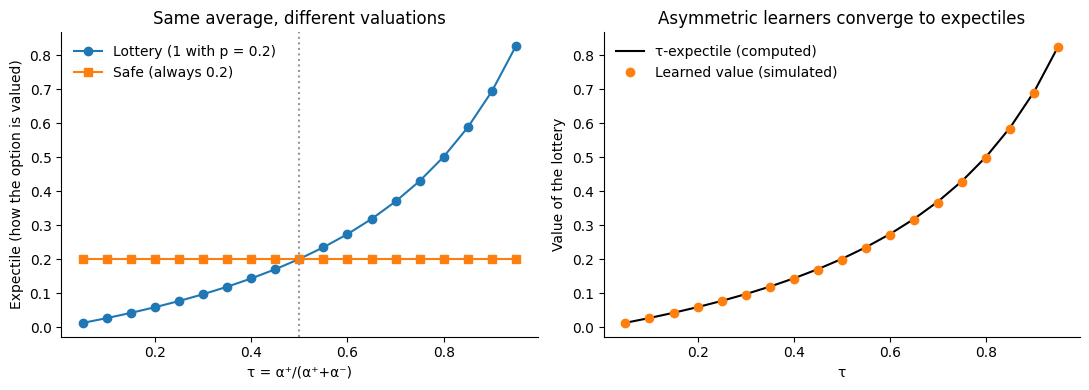

In [5]:
TOTAL = 0.05
a_pos, a_neg = tau_to_rates(TAU_GRID, TOTAL)
Q = np.full(len(TAU_GRID), 0.2)
learned = []
for step in range(40_000):
    r = float(rng.random() < 0.2)              # same lottery draw for every learner
    delta = r - Q
    Q = Q + np.where(delta > 0, a_pos, a_neg) * delta
    if step >= 20_000:
        learned.append(Q.copy())
learned = np.mean(learned, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(TAU_GRID, exp_lottery, "o-", label="Lottery (1 with p = 0.2)")
axes[0].plot(TAU_GRID, exp_safe, "s-", label="Safe (always 0.2)")
axes[0].axvline(0.5, ls=":", c="0.6")
axes[0].set(xlabel="τ = α⁺/(α⁺+α⁻)", ylabel="Expectile (how the option is valued)",
            title="Same average, different valuations")
axes[0].legend(frameon=False)
axes[1].plot(TAU_GRID, exp_lottery, "k-", label="τ-expectile (computed)")
axes[1].plot(TAU_GRID, learned, "o", c="tab:orange", label="Learned value (simulated)")
axes[1].set(xlabel="τ", ylabel="Value of the lottery", title="Asymmetric learners converge to expectiles")
axes[1].legend(frameon=False)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/04_expectile_intuition.png", dpi=150); plt.show()

## 2. Evolve the two resident populations
Same evolutionary settings as notebooks 02–03. I keep the final population from each run.

In [6]:
CONDITIONS = {
    "High temptation (T = 5, noise 0.05)":   dict(temptation=5.0, noise=0.05),
    "Low temptation (T = 3.5, noise 0.20)":  dict(temptation=3.5, noise=0.20),
}
N_RES_SEEDS, N_GEN = 3, 150
residents = {}
for name, kw in CONDITIONS.items():
    pops = []
    for seed in range(N_RES_SEEDS):
        out = evolve(ipd_lifetime, n_generations=N_GEN, seed=seed, **kw)
        pops.append((out["final_a_pos"], out["final_a_neg"]))
    residents[name] = pops
    tau = np.concatenate([p / (p + n) for p, n in pops])
    total = np.concatenate([p + n for p, n in pops])
    print(f"{name}: resident tau = {tau.mean():.2f}, alpha+ + alpha- = {total.mean():.2f}")

High temptation (T = 5, noise 0.05): resident tau = 0.91, alpha+ + alpha- = 0.97
Low temptation (T = 3.5, noise 0.20): resident tau = 0.34, alpha+ + alpha- = 1.28


## 3. Fitness landscape: which τ does best against the residents?
For each resident population, I create 200 test agents at each τ (19 values). They all share the residents'
average total learning rate, so only the asymmetry differs. Each test agent plays the IPD against randomly drawn
residents (4 partners × 100 rounds), exactly like an evolutionary lifetime.

**How to read the plot:** the curve shows what each τ earns. If the peak sits near the residents' own τ
(dotted line), the evolved bias is stable: no other bias would do better in that world.

In [7]:
N_PER_TAU = 200
landscape = {}
for name, kw in CONDITIONS.items():
    fits, coops, qgaps = [], [], []
    for seed, (r_pos, r_neg) in enumerate(residents[name]):
        rng = np.random.default_rng(100 + seed)
        total = (r_pos + r_neg).mean()
        taus = np.repeat(TAU_GRID, N_PER_TAU)
        m_pos, m_neg = tau_to_rates(taus, total)
        out = ipd_invasion(m_pos, m_neg, r_pos, r_neg, rng, **kw)
        fits.append(out["fitness"].reshape(len(TAU_GRID), N_PER_TAU).mean(1))
        coops.append(out["coop"].reshape(len(TAU_GRID), N_PER_TAU).mean(1))
        qgaps.append(out["qgap"].reshape(len(TAU_GRID), N_PER_TAU, 3).mean(1))
    landscape[name] = dict(fitness=np.array(fits), coop=np.array(coops), qgap=np.array(qgaps))
    best = TAU_GRID[np.mean(fits, 0).argmax()]
    res_tau = np.mean([(p / (p + n)).mean() for p, n in residents[name]])
    print(f"{name}: best tau = {best:.2f}   (residents' tau = {res_tau:.2f})")

pd.DataFrame([dict(condition=name, tau=t, fitness=f, coop=c)
              for name, d in landscape.items()
              for t, f, c in zip(TAU_GRID, d["fitness"].mean(0), d["coop"].mean(0))]
            ).to_csv("results/mechanism_landscape.csv", index=False)

High temptation (T = 5, noise 0.05): best tau = 0.90   (residents' tau = 0.91)
Low temptation (T = 3.5, noise 0.20): best tau = 0.25   (residents' tau = 0.34)


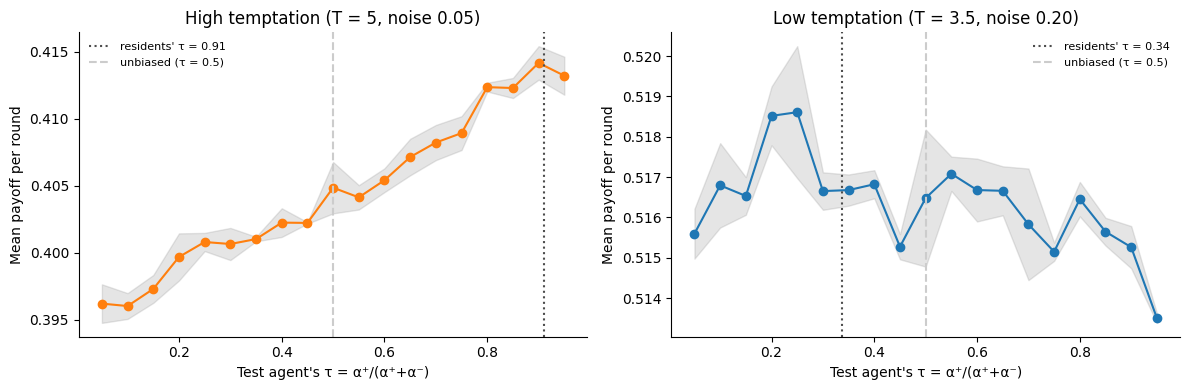

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (name, d) in zip(axes, landscape.items()):
    m, se = d["fitness"].mean(0), d["fitness"].std(0) / np.sqrt(N_RES_SEEDS)
    ax.plot(TAU_GRID, m, "o-", c="tab:orange" if "High" in name else "tab:blue")
    ax.fill_between(TAU_GRID, m - se, m + se, alpha=0.2, color="0.5")
    res_tau = np.mean([(p / (p + n)).mean() for p, n in residents[name]])
    ax.axvline(res_tau, ls=":", c="0.3", label=f"residents' τ = {res_tau:.2f}")
    ax.axvline(0.5, ls="--", c="0.8", label="unbiased (τ = 0.5)")
    ax.set(title=name, xlabel="Test agent's τ = α⁺/(α⁺+α⁻)", ylabel="Mean payoff per round")
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/04_fitness_landscape.png", dpi=150); plt.show()

## 4. Behaviour: what do agents with different τ learn to do?
For each τ: how often test agents (intend to) cooperate, and their final preference for cooperating over defecting
in each situation: **Q(C) − Q(D)** after the partner cooperated vs after the partner defected
(positive = prefers to cooperate).

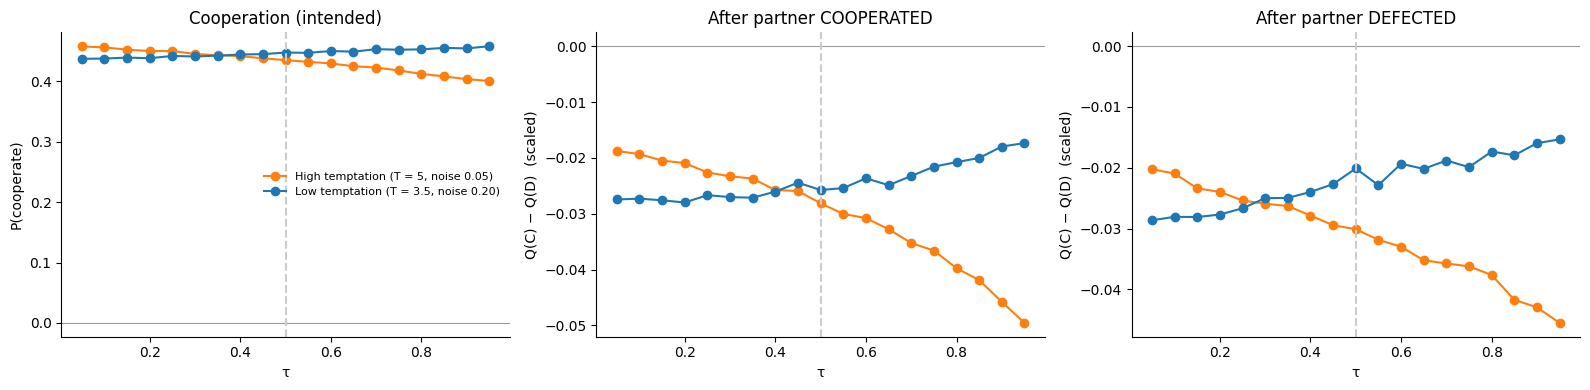

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, d in landscape.items():
    c = "tab:orange" if "High" in name else "tab:blue"
    axes[0].plot(TAU_GRID, d["coop"].mean(0), "o-", c=c, label=name)
    axes[1].plot(TAU_GRID, d["qgap"].mean(0)[:, 0], "o-", c=c, label=name)
    axes[2].plot(TAU_GRID, d["qgap"].mean(0)[:, 1], "o-", c=c, label=name)
axes[0].set(title="Cooperation (intended)", xlabel="τ", ylabel="P(cooperate)")
axes[1].set(title="After partner COOPERATED", xlabel="τ", ylabel="Q(C) − Q(D)  (scaled)")
axes[2].set(title="After partner DEFECTED", xlabel="τ", ylabel="Q(C) − Q(D)  (scaled)")
for ax in axes:
    ax.axhline(0, c="0.6", lw=0.8); ax.axvline(0.5, ls="--", c="0.8")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figures/04_behaviour_by_tau.png", dpi=150); plt.show()

## 5. Expectiles of the outcomes agents actually experience
Here I let **unbiased** test agents (τ = 0.5) play against the residents and record, in the last 50 rounds
with each partner, the outcomes that follow each choice: the TD target *r + γ·max Q(next)*, i.e. "what this
move turned out to be worth".

Then I ask: if an agent valued these outcomes by their τ-expectile, would **cooperating** or **defecting** look
better? The plot shows **expectile(C) − expectile(D)** across τ, separately after the partner cooperated and after
the partner defected. Where the curve crosses zero is the τ at which the ranking flips.

*Caveat:* the outcomes come from unbiased agents' experience, so this is an approximation: it shows how the
evolved partners' behaviour shapes the outcome distributions, not a full equilibrium analysis.

High temptation (T = 5, noise 0.05) | after partner cooperated: 69645 cooperate samples, 90593 defect samples
High temptation (T = 5, noise 0.05) | after partner defected: 104975 cooperate samples, 134787 defect samples
Low temptation (T = 3.5, noise 0.20) | after partner cooperated: 85974 cooperate samples, 99169 defect samples
Low temptation (T = 3.5, noise 0.20) | after partner defected: 100198 cooperate samples, 114659 defect samples


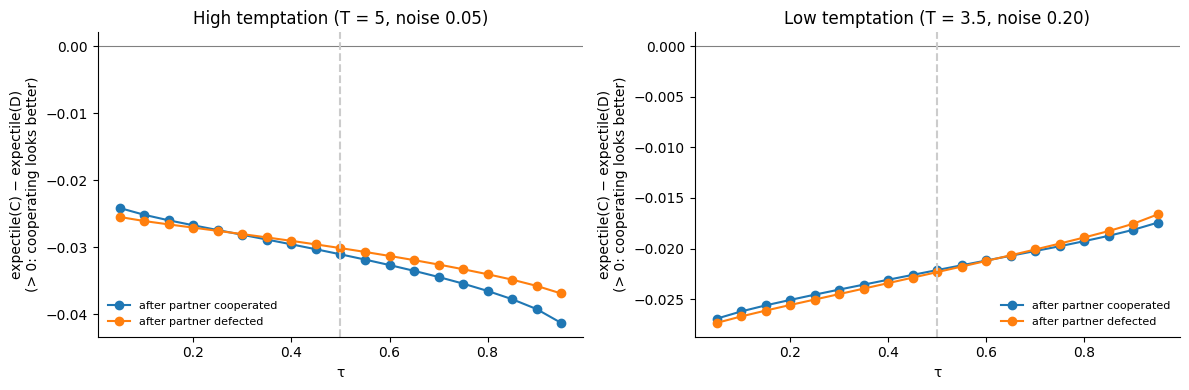

In [10]:
exp_gap = {}
for name, kw in CONDITIONS.items():
    rng = np.random.default_rng(7)
    r_pos = np.concatenate([p for p, n in residents[name]])
    r_neg = np.concatenate([n for p, n in residents[name]])
    total = (r_pos + r_neg).mean()
    m_pos, m_neg = tau_to_rates(np.full(2000, 0.5), total)
    out = ipd_invasion(m_pos, m_neg, r_pos, r_neg, rng, record_targets=True, **kw)
    T = out["targets"]
    gaps = {}
    for state, label in [(0, "after partner cooperated"), (1, "after partner defected")]:
        xc, xd = T[(state, 0)] * 0.1, T[(state, 1)] * 0.1      # scale by (1 - gamma) for readability
        print(f"{name} | {label}: {len(xc)} cooperate samples, {len(xd)} defect samples")
        if len(xc) > 30 and len(xd) > 30:
            gaps[label] = np.array([expectile(xc, t) - expectile(xd, t) for t in TAU_GRID])
    exp_gap[name] = gaps

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, gaps) in zip(axes, exp_gap.items()):
    for label, g in gaps.items():
        ax.plot(TAU_GRID, g, "o-", label=label)
    ax.axhline(0, c="0.5", lw=0.8); ax.axvline(0.5, ls="--", c="0.8")
    ax.set(title=name, xlabel="τ", ylabel="expectile(C) − expectile(D)\n(> 0: cooperating looks better)")
    ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/04_expectile_gap.png", dpi=150); plt.show()

## 6. My interpretation
*(Fill in after running. Guiding questions:)*
1. In each world, where does the fitness landscape peak? Does it match the residents' τ?
2. How does τ change behaviour: do optimists cooperate more, or defect more, after each partner move?
3. In section 5, at which τ does cooperating start to look better than defecting? Does this differ between the
   high- and low-temptation worlds in a way that matches which bias evolves?
4. If the expectile story does **not** fit cleanly, what else could matter? (Hint: agents only live 100 rounds
   per partner, so *how fast* they learn may matter as much as *where their values end up*.)